# Event positions from the delays between channels (`xdel`, `ydel`), and the integrals over them

*Second notebook of `relcal`. Draft prepared with Claude Code for A. Villano, 2026-10-30.*

The first notebook placed events on the face from the **integrals** of the channels, which is circular for a relative calibration. The Run 76 analysis of the UMN group (Matt Fritts, `example_scripts/fritts/run076/r76_analysis_position_new.c` in the `R76Analysis` repository) places them from the **times** at which the pulses rise, which do not depend on the pulse sizes. His quantities, with `t_X` the 20 % rise time of channel `X` (`PXWKr20` in his code):

| quantity | definition | meaning |
|---|---|---|
| `xdel` | `t_E - (t_C + t_D) / 2 - 1 us` | x position: E against the mean of C and D |
| `ydel` | `0.866 (t_D - t_C) + 9 us` | y position: D against C |
| `phidel` | `atan2(ydel, xdel)` | azimuth of the event |
| `afdel` | `t_F - t_A` | centre disc against the outer ring: the radius |

The `-1` and `+9` are the empirical offsets of his code (his note says so); they are used here as they are and are not derived. The times come from the new `goldsluice` algorithm `rise_crossing` (`fraction = 0.2`): the time, from the start of the trace, at which the rise of the largest pulse crosses 20 % of its height, interpolated between samples. **It is computed on the raw trace, not on a filtered pulse like his `WKr20`, so it is noisier.**

**The data.** The smallest series of the run, `07221203_1744` (64 dumps, 210,413 events), processed with all seven algorithms by `data_analysis/R76/processing/r76-1744-position.dataset.toml` into `C:/NSDF/goldsluice-output/r76-1744-position`. The whole of Run 76 is not processed with `rise_crossing` yet. Only real triggers with a pulse are used, as in the first notebook.

Needs `goldpan` (installed by `requirements.txt`) and the output above. Run with the `darkmatter_cli_env` kernel.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib import colors
from matplotlib.patches import Wedge

from goldpan.dataset import Dataset

In [2]:
_here = Path.cwd().resolve()
DEFINITION = next(p / "data_analysis" / "R76" / "processing" / "r76-1744-position.dataset.toml"
                  for p in [_here, *_here.parents] if (p / "data_analysis" / "R76" / "processing").is_dir())
LETTERS = "ABCDEF"

q = Dataset.open(DEFINITION).processed()                  # the quantities only, no pulses
series, dump, event = (np.asarray(q.quantities[k]).astype(str) if k != "event" else np.asarray(q.quantities[k]) for k in ("series", "dump", "event"))
t = {k: np.asarray(q.quantities[f"Side2p{k}"]["crossing_time_s"], dtype=float) * 1e6 for k in LETTERS}   # microseconds
integral = {k: np.asarray(q.quantities[f"Side2p{k}"]["integral"], dtype=float) for k in LETTERS}
print(f"{len(event):,} events of series {np.unique(series)}")
print(f"{'':28}" + "".join(f"{k:>9}" for k in LETTERS))
print(f"{'median 20 % time (us)':28}" + "".join(f"{np.nanmedian(t[k]):>9.1f}" for k in LETTERS))
print(f"{'events without a time':28}" + "".join(f"{np.isnan(t[k]).mean():>9.1%}" for k in LETTERS))

210,413 events of series ['07221203_1744']
                                    A        B        C        D        E        F
median 20 % time (us)           399.6    399.4    407.7    396.5    404.2    397.4
events without a time            1.1%     3.5%     3.6%     1.1%     1.3%     1.2%


## Real triggers

The trigger type is read from the `.csv` files of the raw dumps and joined by series, dump and event number, exactly as in `integral-on-the-face.ipynb` (the cache `~/goldsluice-output/relcal-trigger.npz` is shared with it; if it is missing it is made here). The events labelled `Unknown` are the real, pulse-triggered ones; the labels `Physics` are the random triggers (see that notebook for the evidence).

In [3]:
import csv

TRIG_CACHE = Path.home() / "goldsluice-output" / "relcal-trigger.npz"
RAW = Path("C:/NSDF/idx")

if not TRIG_CACHE.exists():
    S_, D_, E_, T_ = [], [], [], []
    for f in sorted(RAW.glob("0722*_F[0-9][0-9][0-9][0-9]/*.csv")):
        s, d = f.stem.rsplit("_", 1)
        with open(f, newline="") as fh:
            rows = csv.reader(fh)
            next(rows)
            for row in rows:
                S_.append(s); D_.append(int(d[1:])); E_.append(int(row[0])); T_.append(row[1])
    np.savez(TRIG_CACHE, series=S_, dump=D_, event=E_, trigger_type=T_)
tt = np.load(TRIG_CACHE)

SER = np.unique(tt["series"])
def event_key(s, d, e):
    names, inverse = np.unique(np.asarray(d).astype(str), return_inverse=True)
    dn = np.array([int(x.lstrip("F")) for x in names])[inverse]          # "F0001" or 1 -> 1
    return (np.searchsorted(SER, s).astype(np.int64) * 10_000 + dn) * 100_000_000 + np.asarray(e, dtype=np.int64)

kt = event_key(tt["series"], tt["dump"], tt["event"])
order = np.argsort(kt)
want = event_key(series, dump, event)
where = np.minimum(np.searchsorted(kt[order], want), len(kt) - 1)
assert (kt[order][where] == want).all(), "events without a trigger label"
trigger = tt["trigger_type"][order][where]
print({str(k): int((trigger == k).sum()) for k in np.unique(trigger)})

{'Physics': 3997, 'Unknown': 206416}


## The delays

The same selection as in the first notebook: real triggers, and the sum of the positive offset-subtracted integrals of the six channels, `total`, above `THRESH`. In addition every one of the six times must exist, and the pulses must be one pulse: the largest pulse of each channel is the one that is timed, so an event in which the channels time different pulses (a second pulse in the trace) has delays of hundreds of microseconds. `WINDOW` keeps the delays within a window around zero; the choice is stated, change it and rerun.

In [4]:
I = np.column_stack([integral[k] for k in LETTERS])
S = I - np.median(I, axis=0)
total = np.clip(S, 0, None).sum(axis=1)

THRESH = 2.0                       # ADC counts x s, as in integral-on-the-face.ipynb
WINDOW = 60.0                      # microseconds: delays of the same pulse are a few microseconds, of different pulses hundreds
OFFSET_X, OFFSET_Y = -1.0, 9.0     # the empirical offsets of Fritts's code (his xdel has - 1, his ydel + 9)

T = np.column_stack([t[k] for k in LETTERS])
xdel = t["E"] - 0.5 * (t["C"] + t["D"]) + OFFSET_X
ydel = 0.866 * (t["D"] - t["C"]) + OFFSET_Y
afdel = t["F"] - t["A"]
phidel = np.degrees(np.arctan2(ydel, xdel))

pulse = (trigger == "Unknown") & (total > THRESH)
finite = np.isfinite(T).all(axis=1)
import warnings
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)             # an event with no time at all has an all-nan median
    one_pulse = (np.abs(T - np.nanmedian(T, axis=1, keepdims=True)) < WINDOW).all(axis=1)
use = pulse & finite & one_pulse
print(f"real triggers with total > {THRESH}: {pulse.sum():,}; with six times: {(pulse & finite).sum():,}; "
      f"and all six within {WINDOW:.0f} us of their median: {use.sum():,} ({use.sum() / len(use):.1%} of the series)")
for name, v in [("xdel", xdel), ("ydel", ydel), ("afdel", afdel)]:
    p = np.percentile(v[use], [1, 16, 50, 84, 99])
    print(f"{name:>6}  1/16/50/84/99 %: " + "  ".join(f"{x:7.2f}" for x in p) + "  (us)")

real triggers with total > 2.0: 62,723; with six times: 62,622; and all six within 60 us of their median: 60,562 (28.8% of the series)
  xdel  1/16/50/84/99 %:  -12.66    -7.90     0.90     3.90     9.27  (us)
  ydel  1/16/50/84/99 %:  -11.80    -6.05     0.57     5.35    10.84  (us)
 afdel  1/16/50/84/99 %:   -6.85    -2.86    -1.37     2.70     6.37  (us)


## The detector in the plane of the delays

On the face the sectors are `C` upper left, `D` lower left, `E` right. A later pulse in a channel means an event farther from it: `xdel` grows when `E` is late, so toward `C` and `D`; `ydel` grows when `D` is late, so toward `C`. The `x` axis is therefore drawn **reversed** (as the wiki's `x` axis points to the left on this face), and the detector underneath then has the same orientation as in the first notebook.

The scale is a placeholder: the axes are microseconds, not millimetres, and the radius of the face in microseconds (`R_US`) is not known. It is set so that the face covers the range of the delays; it only places the drawing and is not a measurement.

In [5]:
REGIONS = {   # letter -> (inner radius, outer radius, start angle, end angle) in degrees, radius 1 = the face
    "A": (0.90, 1.00, 0, 360), "B": (0.80, 0.90, 0, 360),
    "C": (0.25, 0.80, 60, 180), "D": (0.25, 0.80, 180, 300), "E": (0.25, 0.80, -60, 60),
    "F": (0.00, 0.25, 0, 360),
}
R_US = 14.0       # PLACEHOLDER: the radius of the face in microseconds of delay

def draw_detector(ax, radius=R_US, alpha=1.0, label=True, lw=1.0):
    """The six regions on `ax`, the face of radius `radius` (data units) centred on the origin; the x axis of `ax` is expected reversed."""
    for k, (r_in, r_out, a0, a1) in REGIONS.items():
        ax.add_patch(Wedge((0, 0), r_out * radius, a0, a1, width=(r_out - r_in) * radius, facecolor="none", edgecolor="k", linewidth=lw, alpha=alpha, zorder=1))
        if label and k in "CDE":
            a = np.deg2rad((a0 + a1) / 2)
            ax.text(-0.52 * radius * np.cos(a), 0.52 * radius * np.sin(a), k, ha="center", va="center", fontsize=12, color="0.25", zorder=5)
    if label:
        ax.text(0, 0, "F", ha="center", va="center", fontsize=9, color="0.25", zorder=5)

# the wedges are drawn in face coordinates, whose x is -xdel: draw them in a mirrored frame by flipping the sign of x
def draw_detector_mirrored(ax, **kw):
    n = len(ax.patches)
    draw_detector(ax, **kw)
    for w in ax.patches[n:]:
        c = w.center
        w.set_center((-c[0], c[1]))
        w.theta1, w.theta2 = 180 - w.theta2, 180 - w.theta1
    ax.set_aspect("equal")

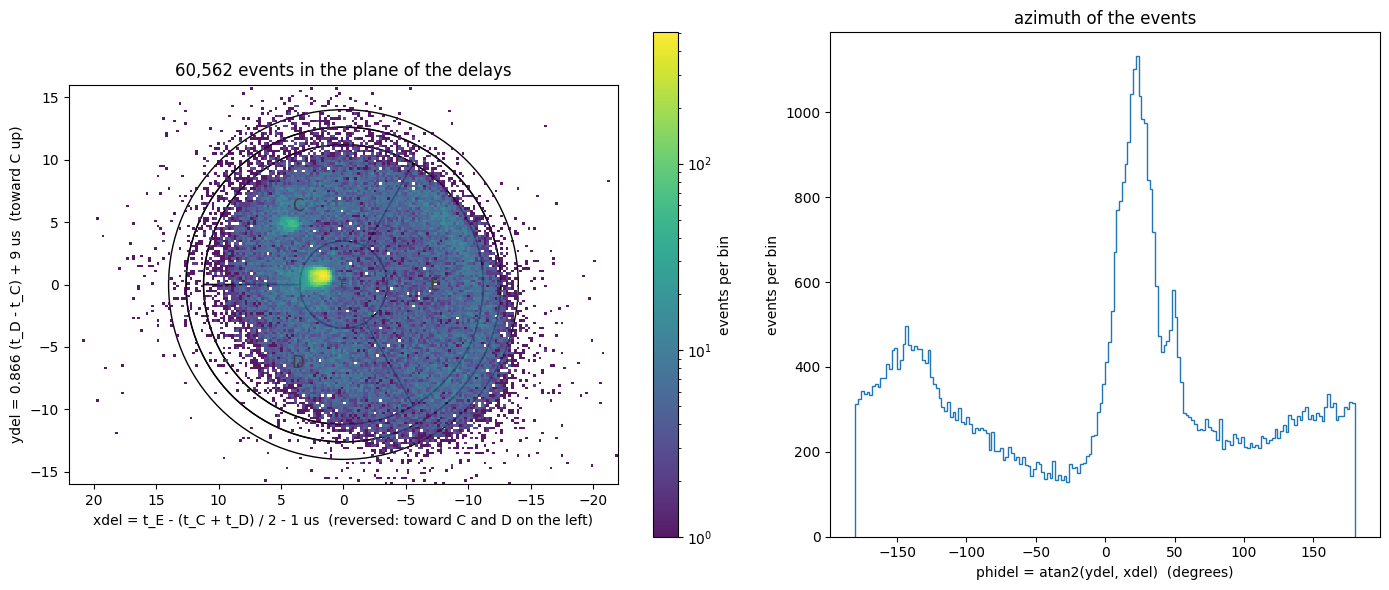

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [1.25, 1]})
h = ax1.hist2d(xdel[use], ydel[use], bins=[200, 160], range=[[-22, 22], [-16, 16]], cmap="viridis", norm=colors.LogNorm(), cmin=1, zorder=2, alpha=0.9)
draw_detector_mirrored(ax1)
ax1.set_xlim(22, -22)                      # x reversed
ax1.set_ylim(-16, 16)
ax1.set_xlabel("xdel = t_E - (t_C + t_D) / 2 - 1 us  (reversed: toward C and D on the left)")
ax1.set_ylabel("ydel = 0.866 (t_D - t_C) + 9 us  (toward C up)")
ax1.set_title(f"{use.sum():,} events in the plane of the delays")
fig.colorbar(h[3], ax=ax1, label="events per bin")

ax2.hist(phidel[use], bins=np.linspace(-180, 180, 181), histtype="step", color="C0")
ax2.set_xlabel("phidel = atan2(ydel, xdel)  (degrees)")
ax2.set_ylabel("events per bin")
ax2.set_title("azimuth of the events")
fig.tight_layout()
plt.show()

## The integral of each channel, over the delay plane

Six maps, one per channel: the mean share of the signal that the channel carries (its positive offset-subtracted integral over `total`) of the events at each place of the plane of the delays, with the detector underneath. This is the same quantity as in the first notebook, but the place of the event now comes from the times, not from the integrals, so a channel with a larger share toward its own sector is a real result and not a consequence of the position being made from it. Places with fewer than 20 events are left blank. Each panel has its own colour scale (1st to 99th percentile of that channel), since the shares differ little between places and a common scale would show nothing; read the colour bars.

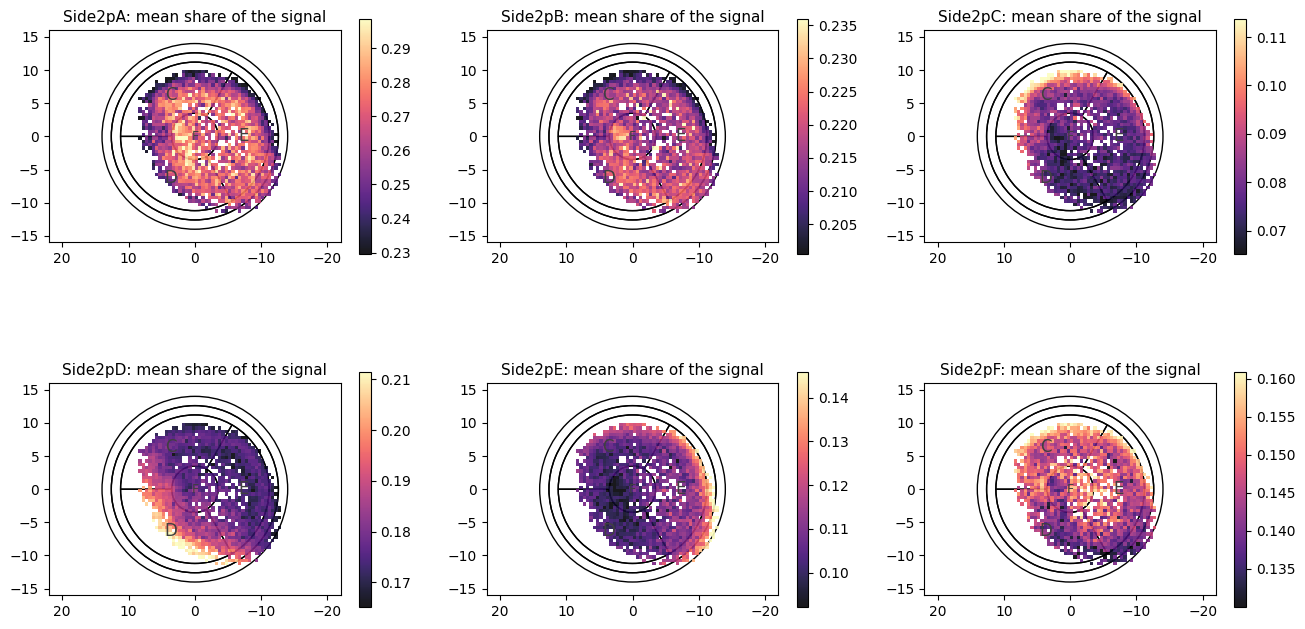

In [7]:
frac = np.clip(S, 0, None) / np.where(total > 0, total, np.nan)[:, None]
xs = np.linspace(-22, 22, 89)
ys = np.linspace(-16, 16, 65)
count, _, _ = np.histogram2d(xdel[use], ydel[use], bins=[xs, ys])

fig, axes = plt.subplots(2, 3, figsize=(16, 8.4))
for ax, i, k in zip(axes.flat, range(6), LETTERS):
    s, _, _ = np.histogram2d(xdel[use], ydel[use], bins=[xs, ys], weights=frac[use, i])
    mean = np.where(count >= 20, s / np.maximum(count, 1), np.nan)
    lo, hi = np.nanpercentile(mean, [1, 99])
    m = ax.pcolormesh(xs, ys, mean.T, cmap="magma", vmin=lo, vmax=hi, zorder=2, alpha=0.9)
    draw_detector_mirrored(ax)
    ax.set_xlim(22, -22)
    ax.set_ylim(-16, 16)
    ax.set_title(f"Side2p{k}: mean share of the signal", fontsize=11)
    fig.colorbar(m, ax=ax, shrink=0.8)
plt.show()

## The two positions against each other

Does the place from the integrals (the first notebook: the integral-weighted centre of the six regions) agree with the place from the delays? Each panel is the event density in the plane of one coordinate from the integrals against the same coordinate from the delays. The delay `x` is reversed in sign so that both point the same way (toward the left of the face, as the wiki's `x` axis).

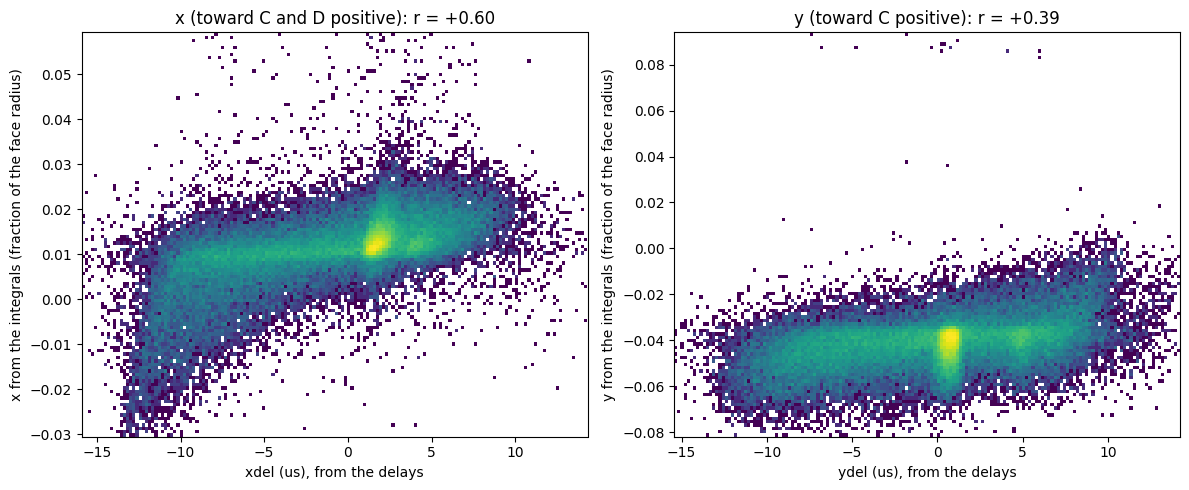

In [8]:
CENTROIDS = {}
for k, (r_in, r_out, a0, a1) in REGIONS.items():
    if a1 - a0 >= 360:
        CENTROIDS[k] = (0.0, 0.0)
        continue
    half = np.deg2rad(a1 - a0) / 2
    r_c = (2 / 3) * (r_out ** 3 - r_in ** 3) / (r_out ** 2 - r_in ** 2) * np.sin(half) / half
    a = np.deg2rad((a0 + a1) / 2)
    CENTROIDS[k] = (r_c * np.cos(a), r_c * np.sin(a))
C = np.array([CENTROIDS[k] for k in LETTERS])
W = np.clip(S[use], 0, None)
pos = (W @ C) / W.sum(axis=1, keepdims=True)        # the integral-weighted centre, face coordinates (x to the right, E on the right)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, a, b, name in [(axes[0], xdel[use], -pos[:, 0], "x (toward C and D positive)"), (axes[1], ydel[use], pos[:, 1], "y (toward C positive)")]:
    ax.hist2d(a, b, bins=[160, 120], range=[np.percentile(a, [0.1, 99.9]), np.percentile(b, [0.1, 99.9])], cmap="viridis", norm=colors.LogNorm(), cmin=1)
    ax.set_xlabel(f"{name[0]}del (us), from the delays")
    ax.set_ylabel(f"{name[0]} from the integrals (fraction of the face radius)")
    ax.set_title(f"{name}: r = {np.corrcoef(a, b)[0, 1]:+.2f}")
fig.tight_layout()
plt.show()

**What this shows, and what is next.** The six channels placed from their rise times, the integrals of the channels over that plane, and the two positions against each other. Not done: the radius (`afdel`), a conversion of the delays to millimetres (`R_US` is a placeholder), the offsets (taken from Fritts's code, not derived), and the whole of Run 76 (this is one series). The times are measured on the raw traces; if the noise in them dominates the delays, filter the pulses first (`goldpan.algorithms.lowpass`) or fit the rise.

Next: reprocess the 12 series with `rise_crossing` (about 2,993 dumps), look at the width of the delay distributions against the filtered version, and fit the ratios of the channels in the sectors.